In [1]:
import numpy as np
import pandas as pd

# from sklearn.neighbors import KernelDensity

import geopandas as gpd
from shapely.geometry import Point, Polygon
import pycno

import matplotlib.pyplot as plt
from matplotlib import cm
# from matplotlib.patches import Patch
# from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import netCDF4 as nc

from pathlib import Path
import os
import glob
import pickle

tab20b = cm.get_cmap("tab20b").colors
tab20c = cm.get_cmap("tab20c").colors
tab20 = cm.get_cmap("tab20").colors
Set2 = cm.get_cmap("Set2").colors
Paired = cm.get_cmap("Paired").colors

biome_colors = {'Boreal Forests/Taiga':tab20[1],'Tundra':tab20c[17],'Deserts & Xeric Shrublands':tab20b[10],
               'Mediterranean Forests, Woodlands & Scrub':tab20b[8],'Montane Grasslands & Shrublands':Set2[5],
               'Flooded Grasslands & Savannas':tab20[5],'Temperate Grasslands, Savannas & Shrublands':Set2[4],
               'Tropical & Subtropical Grasslands, Savannas & Shrublands':tab20[17],
               'Temperate Broadleaf & Mixed Forests':(0.2,0.4,0),'Tropical & Subtropical Moist Broadleaf Forests':tab20[4],
               'Tropical & Subtropical Dry Broadleaf Forests':tab20[16],'Temperate Conifer Forests':Paired[11],
                'Tropical & Subtropical Coniferous Forests':tab20b[5],'Mangrove':[0.27,0.28,0.02],'Lake':[0,0,1],
                'Rock/Ice':[1,1,1]}

kc_dict = {1:'Af;Tropical, rainforest',2:'Am;Tropical, monsoon',3:'Aw;Tropical, savannah',
4:'BWh;Arid, desert, hot',5:'BWk;Arid, desert, cold',6:'BSh;Arid, steppe, hot',7:'BSk;Arid, steppe, cold',
8:'Csa;Temperate, dry summer, hot summer',9:'Csb;Temperate, dry summer, warm summer',10:'Csc;Temperate, dry summer, cold summer',11:'Cwa;Temperate, dry winter, hot summer',
12:'Cwb;Temperate, dry winter, warm summer',13:'Cwc;Temperate, dry winter, cold summer',14:'Cfa;Temperate, no dry season, hot summer',15:'Cfb;Temperate, no dry season, warm summer',
16:'Cfc;Temperate, no dry season, cold summer',17:'Dsa;Cold, dry summer, hot summer',18:'Dsb;Cold, dry summer, warm summer',19:'Dsc;Cold, dry summer, cold summer',
20:'Dsd;Cold, dry summer, very cold winter',21:'Dwa;Cold, dry winter, hot summer',22:'Dwb;Cold, dry winter, warm summer',23:'Dwc;Cold, dry winter, cold summer',
24:'Dwd;Cold, dry winter, very cold winter',25:'Dfa;Cold, no dry season, hot summer',26:'Dfb;Cold, no dry season, warm summer',27:'Dfc;Cold, no dry season, cold summer',
28:'Dfd;Cold, no dry season, very cold winter',29:'ET;Polar, tundra',30:'EF;Polar, frost'}

### Read in GlobalRx file

* Prescriptions for Portugal and Spain [here](https://interior.gencat.cat/web/.content/home/030_arees_dactuacio/bombers/foc_forestal/publicacions_tecniques_i_normativa/guies_tecniques/cremes_prescrites/2010_Handbook-Plan-and-use-Prescribed-Burning-in-Europe_FireParadox.pdf)
* Prescriptions for New South Wales [here](https://www-sciencedirect-com.uea.idm.oclc.org/science/article/pii/S0168192319301091#bib0315)
* Prescriptions for South Australia [here](https://cdn.environment.sa.gov.au/environment/docs/prescribed-burning-operational-prescriptions-field-guide-gen.pdf); used values on pg 17 
* Prescriptions for Queensland [here](https://parks.des.qld.gov.au/__data/assets/pdf_file/0025/152890/pbg-brigalow-belt.pdf); used values on pg 29
* Prescriptions for Sweden
    * [here](https://www.metsa.fi/wp-content/uploads/2017/05/Granstrom_Controlled-burning_Sweden-1.pdf); pg 57
    * [here](https://www.metsa.fi/wp-content/uploads/2017/05/LIFE-TAIGA_Example-monitoring-report-Skattlosberg-1.pdf); pg 5
    * [here](https://www.metsa.fi/wp-content/uploads/2017/05/Lindberg_controlled_burning_Finland-1.pdf); pg 65
* Prescriptions for Northern Great Plains [here](https://fireecology.springeropen.com/articles/10.1186/s42408-019-0027-y#Sec1)
* Prescriptions for Oklahoma [here](https://extension.okstate.edu/fact-sheets/print-publications/e/oklahoma-prescribed-burning-handbook-e-1010.pdf); pg 11
* Prescriptions for South Africa Southwestern Cape [here](https://www.tandfonline.com/doi/pdf/10.1080/00382167.1987.9630282)

In [2]:
# Rx burning meteorological limits

# CA/PNW Forest and Non-forest from Crystal and John
CA_T = [4,30] # Celsius
CA_W = [0,12] # m/s
CA_RH = [15,70] # %

CA_F_T = [7,30]
CA_F_W = [0,10]
CA_F_RH = [15,65]

CA_NF_T = [4,30]
CA_NF_W = [0,12]
CA_NF_RH = [20,70]

CA_SN_T = [3,30]
CA_SN_W = [1,7] # I think this is already a 10m wind speed
CA_SN_RH = [18,68]

OK_T = [-1,43]
OK_W = [4/2.237,25/2.237]
OK_RH = [10,80]
OK_FFDI = []

NGP_T = [2,43]
NGP_W = [5/2.237,18/2.237]
NGP_RH = [20,80]
NGP_FFDI = []

# Page 19, for shrubland burning; 2 meter wind
PRT_T = [8,20] # Celsius
PRT_W = [5/3.6,15/3.6] # m/s, convert to 10m
PRT_RH = [20,70] # %
PRT_FFDI = []

# Page 6, generic window for Spain; 2 meter wind
CAT_T = [] # Celsius
CAT_W = [0/3.6,25/3.6] # m/s
CAT_RH = [25,90] # %
CAT_FFDI = []

# New South Wales Coastal Bioregions from Clarke et al. 2019
NSW_T = [16.5,28.5]
NSW_W = [2/3.6/1.5,27.7/3.6/1.5]
NSW_RH = [30.7,56.4]
NSW_FFDI = [2,13]

# Mount Lofty Eucalypt heathy open forest and woodland
SAUS_T = [15,40]
SAUS_W = [10/3.6/1.28,35/3.6/1.28]
SAUS_RH = [10,60]
SAUS_FFDI = [5,12]

# Brigalow Belt South, Eucalyptus Woodland; already at 10m wind speed
BBS_T = []
BBS_W = [10/3.6,23/3.6] # Convert to m/s
BBS_RH = []
BBS_FFDI = [0,13]
BBS_KBDI = [0,120]

# Sweden
# Granstrom 2017
# SW_T = []
# SW_RH = [30,45]
# SW_W = [0,5]
# SW_FFDI = []
# SW_DMC = [20,65]

# Fernandes and Loureiro 2010; 2 meter wind
# SW_T = [18,30]
# SW_RH = []
# SW_W = [2/3.6,35/3.6]
# SW_FFDI = []
# SW_DMC = [20,65]
# SW_FFMC = [80,90]

# Average of Lundin 2015, Granstrom 2017, and Lindberg 2017
SW_T = []
SW_RH = [31.7,47.5]
SW_W = [0.67,4.83]
SW_FFDI = []
SW_DMC = [27.5,60]
SW_FFMC = [80,90]

# SOUTH-WESTERN CAPE MOUNTAIN CATCHMENT AREAS
SWC_T = [18,28]
SWC_RH = [15,45]
SWC_W = [0,16/3.6]

In [5]:
# # Read in master CSV
df = pd.read_csv('Rx_Master/Rx_MASTER_v2025-02-06.csv',low_memory=False)
# df = pd.read_csv('Rx_Master/US_master.csv',low_memory=False)
df.loc[df['PPT_tot']<0,'PPT_tot'] = 0
df.loc[:,'T_max'] = df['T_max'].values-273.15

df = df.loc[~np.isinf(df['T_max'])].loc[~np.isinf(df['RH_min'])]

# Subsetted dataframes
US_df = df[df['Country']=='United States']

CA_df = df[df['Country']=='United States'].loc[df['State/Province']=='California']
CA_TC_df = CA_df[CA_df['Biome (Olson)']=='Temperate Conifer Forests']
CA_WS_df = CA_df[CA_df['Biome (Olson)']=='Mediterranean Forests, Woodlands & Scrub']
CA_SN_df = CA_df[CA_df['Ecoregion (Olson)']=='Sierra Nevada forests'].loc[CA_df['Topography']>=900]

OK_df = df[df['State/Province']=='Oklahoma']

NGP_df = df[df['Ecoregion (Olson)']=='Northern short grasslands']

PRT_df = df[df['Country']=='Portugal'].loc[df['Latitude']>39.5]
PRT_df['Wind_max'] = PRT_df['Wind_max']*0.67 # Convert from 10m to 2m wind

CAT_df = df[df['Country']=='Spain'].loc[df['State/Province']=='Catalonia']

AUS_IBRA = gpd.read_file('Australia_shp/ibra7_regions.shp').to_crs('EPSG:4326')
NSW_df = df[df['Country']=='Australia'].loc[df['State/Province']=='New South Wales']
NSW_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(NSW_df['Longitude'],NSW_df['Latitude'])]})
NSW_pts.crs = 'EPSG:4326'
NSW_join = gpd.sjoin(NSW_pts,AUS_IBRA.loc[[56,58,68,75]])
NSW_coast_df = NSW_df.iloc[NSW_join.index]

SAUS_df = df[df['Country']=='Australia'].loc[df['State/Province']=='South Australia']
WAUS_df = df[df['Country']=='Australia'].loc[df['State/Province']=='Western Australia']
QNSL_df = df[df['Country']=='Australia'].loc[df['State/Province']=='Queensland']

SAUS_MLW_df = SAUS_df[SAUS_df['Ecoregion (Olson)']=='Mount Lofty woodlands']
QNSL_BTS_df = QNSL_df[QNSL_df['Ecoregion (Olson)']=='Brigalow tropical savanna']

# Brigalow Belt South
BBS_shp = AUS_IBRA[AUS_IBRA['REG_NAME_7']=='Brigalow Belt South']
BBN_shp = AUS_IBRA[AUS_IBRA['REG_NAME_7']=='Brigalow Belt North']
BTS_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(QNSL_BTS_df['Longitude'],QNSL_BTS_df['Latitude'])]})
BTS_pts.crs = 'EPSG:4326'
BTS_join = gpd.sjoin(BTS_pts,BBS_shp)
BTN_join = gpd.sjoin(BTS_pts,BBN_shp)
BBS_df = QNSL_BTS_df.iloc[BTS_join.index]
BBN_df = QNSL_BTS_df.iloc[BTN_join.index]
# BBS_df['Wind_max'] = BBS_df['Wind_max']*0.8
BBS_FOR_df = BBS_df.loc[BBS_df['Fuelbed Classification (GFD-FCCS)']=='Broadleaf Evergreen or Semi-Deciduous Forest (Australia)']
BBS_GRA_df = BBS_df.loc[[True if 'Grassland' in i else False for i in BBS_df['Fuelbed Classification (GFD-FCCS)']]]

BBN_FOR_df = BBN_df.loc[BBN_df['Fuelbed Classification (GFD-FCCS)']=='Broadleaf Evergreen or Semi-Deciduous Forest (Australia)']
BBN_GRA_df = BBN_df.loc[[True if 'Grassland' in i else False for i in BBN_df['Fuelbed Classification (GFD-FCCS)']]]

SW_df = df[df['Country']=='Sweden']
SW_df['Wind_max'] = SW_df['Wind_max']/2.5 # Convert from 10m to 2m wind for long, short, or mixed leaf conifer 

ROR_df = df[[True if 'Roraima' in i else False for i in df['State/Province']]]

KRG_df = df[df['Ecoregion (Olson)']=='Zambezian and Mopane woodlands']

/tmp/ipykernel_1911/3197182469.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SW_df['Wind_max'] = SW_df['Wind_max']/2.5 # Convert from 10m to 2m wind for long, short, or mixed leaf conifer


In [99]:
SW_W_val = SW_df['Fuelbed Group'].map({'Broadleaf Deciduous Forest':0.2,'Flooded Shrubland-Grassland':0.7,'Mixed Broadleaf and Needleleaf Forest':0.15,
          'Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)':0.33,'Needleleaf Evergreen':0.2,
          'Sparse Vegetation':0.8})*SW_df['Wind_max']

Fuelbed Group
Broadleaf Deciduous Forest                              2
Flooded Shrubland-Grassland                            10
Mixed Broadleaf and Needleleaf Forest                  17
Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)    11
Needleleaf Evergreen                                   88
Sparse Vegetation                                       6
dtype: int64

In [105]:
(0.2*2+0.7*10+0.15*17+11*0.33+0.2*88+6*0.8)/134

0.26850746268656717

In [120]:
SW_df = df[df['Country']=='Sweden']
SW_df['Wind_max'] = SW_df['Wind_max']*0.33

/tmp/ipykernel_34950/1951803522.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  SW_df['Wind_max'] = SW_df['Wind_max']*0.33


In [122]:
np.sort(SW_df['Wind_max'].values)

array([0.47079203, 0.58978907, 0.67857782, 0.71789147, 0.73031522,
       0.74785441, 0.78175126, 0.84076894, 0.87112739, 0.87709056,
       0.89900914, 0.91165092, 0.92663639, 0.93041996, 0.95891971,
       0.96011328, 0.96077851, 0.96305259, 0.96469758, 0.96997062,
       0.99743643, 0.99743643, 1.00581302, 1.01112889, 1.0213829 ,
       1.03145222, 1.0354687 , 1.04389088, 1.05029053, 1.05046953,
       1.0514979 , 1.05166957, 1.05201765, 1.05201765, 1.0619752 ,
       1.07391838, 1.07582149, 1.08493584, 1.08716213, 1.09185422,
       1.11252496, 1.11278788, 1.11717013, 1.12519183, 1.12835887,
       1.13664174, 1.14744355, 1.15097208, 1.16169423, 1.18040055,
       1.18928635, 1.19659931, 1.19659931, 1.19659931, 1.20328396,
       1.21441834, 1.21984958, 1.22227363, 1.23136007, 1.2322103 ,
       1.23263013, 1.23344772, 1.23529448, 1.24505743, 1.31001412,
       1.31237999, 1.31441241, 1.31752629, 1.3177517 , 1.32728763,
       1.33269321, 1.33456273, 1.33844144, 1.34293246, 1.36742

### Box and Whisker Plots with Wind, T, and RH

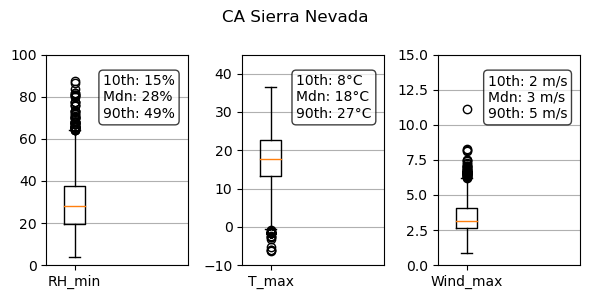

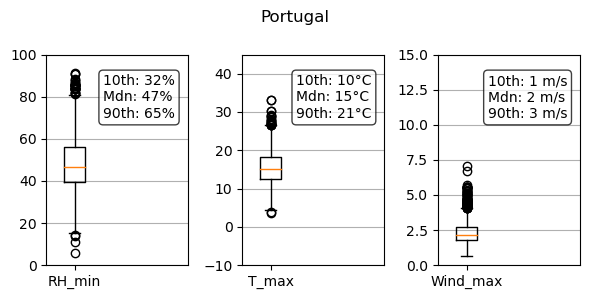

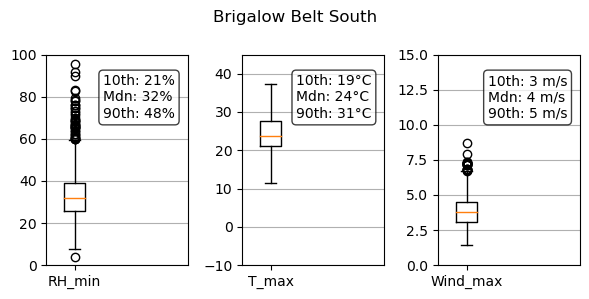

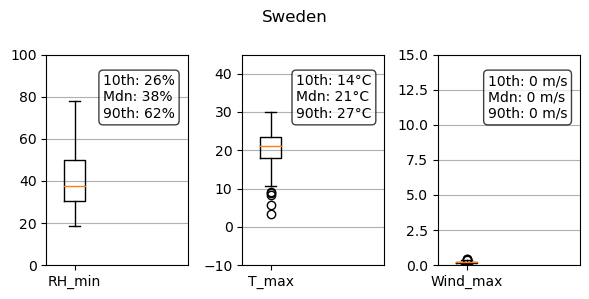

In [108]:
regions = ['CA Sierra Nevada','Portugal',
           'Brigalow Belt South','Sweden']
i=0
for df in [CA_SN_df,PRT_df,BBS_df,SW_df]:
    fig,ax = plt.subplots(1,3,figsize=(6,3))
    RH_md = round(np.median(df['RH_min'].dropna(how='any')))
    RH_90 = round(np.percentile(df['RH_min'].dropna(how='any'),90))
    RH_10 = round(np.percentile(df['RH_min'].dropna(how='any'),10))
    T_md = round(np.median(df['T_max'].dropna(how='any')))
    T_90 = round(np.percentile(df['T_max'].dropna(how='any'),90))
    T_10 = round(np.percentile(df['T_max'].dropna(how='any'),10))
    W_md = round(np.median(df['Wind_max'].dropna(how='any')))
    W_90 = round(np.percentile(df['Wind_max'].dropna(how='any'),90))
    W_10 = round(np.percentile(df['Wind_max'].dropna(how='any'),10))
    
    bp0 = ax[0].boxplot(df['RH_min'].dropna(how='any'),labels=['RH_min'],positions=[0.2])
    bp1 = ax[1].boxplot(df['T_max'].dropna(how='any'),labels=['T_max'],positions=[0.2])
    bp2 = ax[2].boxplot(df['Wind_max'].dropna(how='any'),labels=['Wind_max'],positions=[0.2])
    
    ax[0].set_xlim([0,1])
    ax[0].set_ylim([0,100])
    ax[1].set_xlim([0,1])
    ax[1].set_ylim([-10,45])
    ax[2].set_xlim([0,1])
    ax[2].set_ylim([0,15])
    
    ax[0].grid(axis='y')
    ax[1].grid(axis='y')
    ax[2].grid(axis='y')
    
    ax[0].annotate('10th: '+str(RH_10)+'%'+'\nMdn: '+str(RH_md)+'%'+'\n90th: '+str(RH_90)+'%',xy=(0.4,0.7),xycoords='axes fraction',
                  bbox = dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None))
    deg = u'\N{DEGREE SIGN}'
    ax[1].annotate('10th: '+str(T_10)+deg+'C'+'\nMdn: '+str(T_md)+deg+'C'+'\n90th: '+str(T_90)+deg+'C',xy=(0.38,0.7),xycoords='axes fraction',
                  bbox = dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None))
    ax[2].annotate('10th: '+str(W_10)+' m/s'+'\nMdn: '+str(W_md)+' m/s'+'\n90th: '+str(W_90)+' m/s',xy=(0.35,0.7),xycoords='axes fraction',
                  bbox = dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None))
    
    fig.suptitle(regions[i])
    i+=1
    plt.tight_layout()

In [11]:
df = CA_SN_df
print('RH_min')
print(df['RH_min'].min())
print(df['RH_min'].max())
print(np.percentile(df['RH_min'].dropna(how='any'),10))
print(np.percentile(df['RH_min'].dropna(how='any'),90))
print('T2m')
print(df['T_max'].min())
print(df['T_max'].max())
print(np.percentile(df['T_max'].dropna(how='any'),10))
print(np.percentile(df['T_max'].dropna(how='any'),90))
print('Wind_max')
print(df['Wind_max'].min())
print(df['Wind_max'].max())
print(np.percentile(df['Wind_max'].dropna(how='any'),10))
print(np.percentile(df['Wind_max'].dropna(how='any'),90))
print('DMC')
print(df['DMC'].min())
print(df['DMC'].max())
print(np.percentile(df['DMC'].dropna(how='any'),10))
print(np.percentile(df['DMC'].dropna(how='any'),90))
print('FFMC')
print(df['FFMC'].min())
print(df['FFMC'].max())
print(np.percentile(df['FFMC'].dropna(how='any'),10))
print(np.percentile(df['FFMC'].dropna(how='any'),90))

RH_min
3.978580949323998
87.60016662821083
14.858943695088742
49.08508663119387
T2m
-6.319433034698022
36.41047261538921
7.681733514965299
26.95202736167599
Wind_max
0.8914336679098482
11.130040266660943
2.1357662586240838
4.970942117351778
DMC
0.0
672.75
5.0
200.0
FFMC
6.208984375
98.517578125
58.017578125
95.125


### 2D Histograms with Wind, T, and RH

In [5]:
def Rx_burn_pct(df,T_lim,RH_lim,W_lim):
    
    if T_lim and RH_lim and W_lim:
        tot_burn_pct = len(df[(df['Wind']<W_lim[1])&
                    (df['Wind']>W_lim[0])&
                    (df['RH']<RH_lim[1])&
                    (df['RH']>RH_lim[0])&
                    (df['T2m']<T_lim[1])&
                    (df['T2m']>T_lim[0])])/len(df)
    elif T_lim and RH_lim:
        tot_burn_pct = len(df[(df['RH']<RH_lim[1])&
                (df['RH']>RH_lim[0])&
                (df['T2m']<T_lim[1])&
                (df['T2m']>T_lim[0])])/len(df)
    elif W_lim and RH_lim:
        tot_burn_pct = len(df[(df['Wind']<W_lim[1])&
                (df['Wind']>W_lim[0])&
                (df['RH']<RH_lim[1])&
                (df['RH']>RH_lim[0])])/len(df)
    elif T_lim and W_lim:
        tot_burn_pct = len(df[(df['Wind']<W_lim[1])&
                (df['Wind']>W_lim[0])&
                (df['T2m']<T_lim[1])&
                (df['T2m']>T_lim[0])])/len(df)
    
    return tot_burn_pct

In [6]:
def plot2d_Rx(df,var2,var1,varlim2,varlim1,region):
    
    df_clean = df.dropna(how='any',subset=[var1,var2])
    if varlim1 and varlim2:
        burn_pct = len(df_clean[(df_clean[var1]<=varlim1[1])&(df_clean[var1]>=varlim1[0])&(df_clean[var2]<=varlim2[1])&(df_clean[var2]>=varlim2[0])])/len(df_clean)
    fig,ax = plt.subplots(2,2,gridspec_kw={'width_ratios':[5,1],'height_ratios':[1,5]},figsize=(6,6),
                          sharex='col',sharey='row')
    ax = ax.ravel()
        
    if (var1 == 'Wind') or (var1 == 'Wind_max') or (var1 == 'Wind_mean'):
        col1 = 'green'
        ylabel = 'Wind Speed, m/s'
        ylim = [0,10]
        W_lim = varlim1
        ticks1 = [1,3,5,7,9]
        var1_lab = 'Wind'
    if (var2 == 'Wind') or (var2 == 'Wind_max') or (var2 == 'Wind_mean'):
        col2 = 'green'
        xlabel = 'Wind Speed, m/s'
        xlim = [0,10]
        W_lim = varlim2
        ticks2 = [1,3,5,7,9]
        var2_lab = 'Wind'
    if (var1 == 'RH') or (var1 == 'RH_min') or (var1 == 'RH_mean'):
        col1 = 'blue'
        ylabel = 'Relative Humidity, %'
        ylim = [0,100]
        RH_lim = varlim1
        ticks1 = [10,30,50,70,90]
        var1_lab = 'RH'
    if (var2 == 'RH') or (var2 == 'RH_min') or (var2 == 'RH_mean'):
        col2 = 'blue'
        xlabel = 'Relative Humidity, %'
        xlim = [0,100]
        RH_lim = varlim2
        var2_lab = 'RH'
        ticks2 = [10,30,50,70,90]
    if var1 == 'T_max':
        col1 = 'darkorange'
        ylabel = '2-Meter Temperature, '+u'\N{DEGREE SIGN}'+'C'
        ylim = [0,40]
        T_lim = varlim1
        var1_lab = 'T2m'
        ticks1 = [0,5,10,15,20,25,30,35,40]
    if var2 == 'T_max':
        col2 = 'darkorange'
        xlabel = '2-Meter Temperature, '+u'\N{DEGREE SIGN}'+'C'
        xlim = [0,40]
        T_lim = varlim2
        var2_lab = 'T2m'
        ticks2 = [0,5,10,15,20,25,30,35,40]
    if var1 == 'FFDI':
        col1 = 'gold'
        ylabel = 'McArthur Forest Fire Danger Index'
        ylim = [0,30]
        FFDI_lim = varlim1
        var1_lab = var1
        ticks1 = [5,10,15,20,25]
    if var2 == 'FFDI':
        col2 = 'gold'
        xlabel = 'McArthur Forest Fire Danger Index'
        xlim = [0,30]
        FFDI_lim = varlim2
        var2_lab = var2
        ticks2 = [5,10,15,20,25]
    if var1 == 'DMC':
        col1 = 'purple'
        ylabel = 'Duff Moisture Code'
        ylim = [0,90]
        FFDI_lim = varlim1
        var1_lab = var1
        ticks1 = [10,30,50,70,90]
    if var2 == 'DMC':
        col2 = 'purple'
        xlabel = 'Duff Moisture Code'
        xlim = [0,90]
        FFDI_lim = varlim2
        var2_lab = var2
        ticks2 = [10,30,50,70,90]
    if var1 == 'KBDI':
        col1 = 'deeppink'
        ylabel = 'Keetch-Byram Drought Index'
        ylim = [0,90]
        FFDI_lim = varlim1
        var1_lab = var1
        ticks1 = [20,40,60,80,100]
    if var2 == 'KBDI':
        col2 = 'deeppink'
        xlabel = 'Keetch-Byram Drought Index'
        xlim = [0,120]
        FFDI_lim = varlim2
        var2_lab = var2
        ticks2 = [20,40,60,80,100]
    if var1 == 'FFMC':
        col1 = 'maroon'
        ylabel = 'Fine Fuel Moisture Code'
        ylim = [40,100]
        FFDI_lim = varlim1
        var1_lab = var1
        ticks1 = [50,60,70,80,90]
    if var2 == 'FFMC':
        col2 = 'maroon'
        xlabel = 'Fine Fuel Moisture Code'
        xlim = [40,100]
        FFDI_lim = varlim2
        var2_lab = var2
        ticks2 = [50,60,70,80,90]
        
    counts = ax[0].hist(df_clean[var2].values,bins=20,color=col2,edgecolor='black',linewidth=0.4)
    if varlim2:
        var2_pct = 100*len(df_clean[(df_clean[var2]<varlim2[1])&(df_clean[var2]>varlim2[0])])/len(df_clean)
        vlines = ax[0].vlines(varlim2,ymin=0,ymax=max(counts[0])*1.1,colors='red',label=str(round(var2_pct))+'% Burns in\n'+var2_lab+' Range')
        if len(str(round(var2_pct)))>2:
            x = 0.7
        else:
            if ('FFMC' in var2):
                x = 0.02
            else:
                x = 0.725
        ax[0].annotate(str(round(var2_pct))+'% Burns in\n'+var2_lab+' Range',xy=(x,0.55),xycoords='axes fraction',fontsize=10,
                      color=col2,bbox=dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None),weight='bold')
    ax[0].set_ylim([0,max(counts[0])*1.1])

    ax[2].hist2d(df_clean[var2].values,df_clean[var1].values,bins=20)
    ax[2].set_xlabel(xlabel,fontsize=16,color=col2,weight='bold')
    ax[2].set_ylabel(ylabel,fontsize=16,color=col1,weight='bold')
    ax[2].set_xlim(xlim)
    ax[2].set_ylim(ylim)
    ax[2].set_facecolor([68/255,1/255,84/255])
    if varlim2 and varlim1:
        vlines = ax[2].vlines(varlim2,ymin=varlim1[0],ymax=varlim1[1],colors='red',label='Prescription for\n'+var2_lab+' and '+var1_lab)
        hlines = ax[2].hlines(varlim1,xmin=varlim2[0],xmax=varlim2[1],colors='red')
        ax[2].annotate(str(round(burn_pct*100))+'% Burns in '+var2_lab+'\nand '+var1_lab+' Range',xy=(0.603,0.78),xycoords='axes fraction',
                      color='k',bbox = dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None),weight='bold')
        leg = ax[2].legend(handles=[vlines])

    ax[1].set_xticks([])
    ax[1].set_yticks([])
    ax[1].spines[['right','left','top','bottom']].set_visible(False)

    counts = ax[3].hist(df_clean[var1].values,bins=20,orientation='horizontal',color=col1,edgecolor='black',linewidth=0.4)
    if varlim1:
        var1_pct = 100*len(df_clean[(df_clean[var1]<=varlim1[1])&(df_clean[var1]>=varlim1[0])])/len(df_clean)
        vlines = ax[3].hlines(varlim1,xmin=0,xmax=max(counts[0])*1.1,colors='red',label=str(round(var1_pct))+'% Burns in\n'+var1_lab+' Range')
        if len(str(round(var1_pct)))>2:
               y = 0.695
        else:
            if ('FFMC' in var1):
                y = 0.04
            else:
                y = 0.72
        ax[3].annotate(str(round(var1_pct))+'% Burns in\n'+var1_lab+' Range',xy=(0.54,y),xycoords='axes fraction',fontsize=10,weight='bold',
                      color=col1,bbox = dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None),rotation=-90)
    ax[3].set_xlim([0,max(counts[0])*1.1])

    start_year = np.unique(df_clean['Year'])[0]
    end_year = np.unique(df_clean['Year'])[-1]
    plt.suptitle(region+' Rx Burns '+str(start_year)+'-'+str(end_year))
    plt.tight_layout()
    fig.patch.set_alpha(0.0)
    
    if df['Country'].iloc[0]=='Sweden' and len(SW_T)!=0 and (((var1=='RH' and var2=='T_max') or (var1=='T_max' and var2=='RH')) 
                                            or ((var1=='RH_min' and var2=='T_max') or (var1=='T_max' and var2=='RH_min'))
                                            or ((var1=='RH_mean' and var2=='T_max') or (var1=='T_max' and var2=='RH_mean'))):
        if (var1=='RH') or (var2=='RH'):
            RH = 'RH'
        if (var1=='RH_min') or (var2=='RH_min'):
            RH = 'RH_min'
        if (var1=='RH_mean') or (var2=='RH_mean'):
            RH = 'RH_mean'
        RH_pct = 100*len(df_clean[(df_clean[RH]>=df_clean['T_max'])])/len(df_clean)
        if 'RH' in var2:
            ax[0].annotate(str(round(RH_pct))+'% Burns in\n'+'RH Range',xy=(0.725,0.55),xycoords='axes fraction',fontsize=10,
                          color='blue',bbox=dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None),weight='bold')
        else:
            ax[3].annotate(str(round(RH_pct))+'% Burns in\n'+'RH Range',xy=(0.54,0.72),xycoords='axes fraction',fontsize=10,
                          color='blue',bbox=dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None),weight='bold',rotation=-90)
        ax[2].plot(np.arange(0,42),np.arange(0,42),color='red')
        
        try:
            hlines = ax[2].hlines(varlim1[0],xmin=varlim1[0],xmax=100,colors='red',label='Prescription for\n'+var1_lab+' and '+var2_lab)
            ax[2].hlines(varlim1[1],xmin=varlim1[1],xmax=100,colors='red')
        except:
            vlines = ax[2].vlines(varlim2[0],ymin=varlim2[0],ymax=100,colors='red',label='Prescription for\n'+var2_lab+' and '+var1_lab)
            ax[2].vlines(varlim2[1],ymin=varlim2[1],ymax=100,colors='red')
        burn_pct = len(df_clean[(df_clean['T_max']<=SW_T[1])&(df_clean['T_max']>=SW_T[0])&(df_clean[RH]>=df_clean['T_max'])])/len(df_clean)
        ax[2].annotate(str(round(burn_pct*100))+'% Burns in '+var2_lab+'\nand '+var1_lab+' Range',xy=(0.604,0.78),xycoords='axes fraction',
                      color='k',bbox = dict(boxstyle='round',facecolor='white',alpha=0.75,edgecolor=None),weight='bold')
        try:
            leg = ax[2].legend(handles=[hlines])
        except:
            leg = ax[2].legend(handles=[vlines])
    fig.savefig('Figures/'+region+'_2dhist_'+var1+'_'+var2+'.png',transparent=False,bbox_inches='tight')

In [97]:
len(SW_df[(SW_df['FFMC']>=SW_FFMC[0])&(SW_df['FFMC']<=SW_FFMC[1])&(SW_df['RH_min']>SW_df['T2m'])])/len(SW_df)

0.5671641791044776

In [129]:
len(PRT_df[(PRT_df['RH_min']>=PRT_RH[0])&(PRT_df['RH_min']<=PRT_RH[1])&(PRT_df['Wind_max']>=PRT_W[0])&(PRT_df['Wind_max']<=PRT_W[1])])/len(PRT_df)

0.8347793285552622

In [115]:
len(SW_df[(SW_df['FFMC']>=SW_FFMC[0])&(SW_df['FFMC']<=SW_FFMC[1])
           &(SW_df['Wind_max']>=SW_W[0])&(SW_df['Wind_max']<=SW_W[1])
          &(SW_df['DMC']>=SW_DMC[0])&(SW_df['DMC']<=SW_DMC[1])
         &(SW_df['RH_min']>=SW_RH[0])&(SW_df['RH_min']<=SW_RH[1])])/len(SW_df)

0.12686567164179105

In [58]:
FFMC_ID = SW_df[SW_df['FFMC']>SW_FFMC[1]]['ID'].values
RH_ID = SW_df[SW_df['RH_min']<SW_RH[0]]['ID'].values

In [68]:
DMC_ID = SW_df[SW_df['DMC']<SW_DMC[0]]['ID'].values

In [73]:
[i for i in list(set(FFMC_ID).intersection(RH_ID))]

['Rx20180521-N56.915299-E 15.256347',
 'Rx20180514-N59.828594-E 16.003498',
 'Rx20160616-N63.442645-E 17.114233',
 'Rx20160614-N59.861908-E 14.840077',
 'Rx20180522-N64.591033-E 20.030729',
 'Rx20180608-N56.854118-E 15.330859',
 'Rx20180522-N61.746511-E 14.607138',
 'Rx20200615-N62.675450-E 15.925828',
 'Rx20150703-N62.660946-E 15.909092',
 'Rx20160512-N57.258241-E 15.218338',
 'Rx20200624-N67.453632-E 22.817456',
 'Rx20180524-N64.599836-E 20.020923',
 'Rx20180522-N61.624444-E 14.702203',
 'Rx20180524-N64.461871-E 19.057335',
 'Rx20160614-N59.864200-E 14.836916',
 'Rx20200601-N64.278880-E 20.084573',
 'Rx20180516-N58.844858-E 15.381684',
 'Rx20180524-N64.593636-E 20.032464',
 'Rx20160614-N59.865521-E 14.832320',
 'Rx20200601-N60.440738-E 13.877324',
 'Rx20180516-N56.941526-E 15.258665',
 'Rx20180703-N67.446719-E 22.791214']

In [53]:
SW_df[SW_df['RH_min']<SW_RH[0]].groupby(['Month']).size()

Month
4     2
5    17
6    15
7     3
dtype: int64

In [77]:
SW_df[SW_df['DMC']<SW_DMC[0]].groupby(['Month']).size()

Month
1     1
4     1
5    15
6    15
7    23
8    10
9     2
dtype: int64

In [62]:
# plot2d_Rx(CA_SN_df[(CA_SN_df['WDPA Name']=='Yosemite')|(CA_SN_df['WDPA Name']=='Yosemite National Park')],'RH_min','Wind_max',[15,68],CA_SN_W,'CA Sierra Nevada')

In [55]:
np.percentile(BBS_df['RH_min'].values,10)

20.94013827438816

In [34]:
SW_df[(SW_df['Month']==8)&(SW_df['Day']==21)].iloc[0:2]['RH_min']

47435    33.805849
47437    33.805849
Name: RH_min, dtype: float64

In [43]:
SW_df[(SW_df['Month']==6)&(SW_df['Day']==14)&(SW_df['Year']==2016)]['RH_min']

47431    27.277429
47460    27.277429
47461    27.277429
47491    58.186657
47530    25.581152
Name: RH_min, dtype: float64

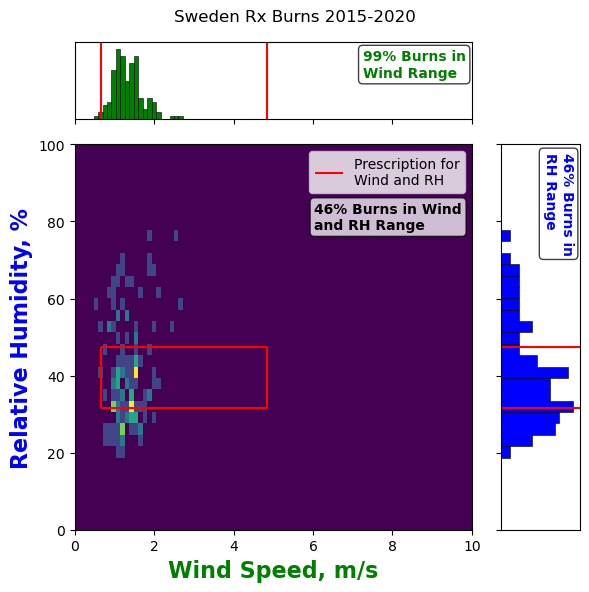

In [125]:
plot2d_Rx(SW_df,'Wind_max','RH_min',SW_W,SW_RH,'Sweden')

Text(0.5, 0, 'Daily T_max')

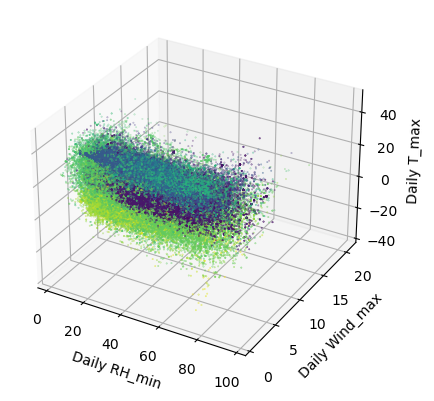

In [64]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
# np.histogramdd(df[['T_max','Wind_max','RH_min']].dropna().values,bins=30)
var1 = 'RH_min'
var2 = 'Wind_max'
var3 = 'T_max'
ax.scatter(df[var1].values,df[var2].values,df[var3].values,c=df['Latitude'].values,s=0.1)
ax.set_xlabel('Daily '+var1)
ax.set_ylabel('Daily '+var2)
ax.set_zlabel('Daily '+var3)

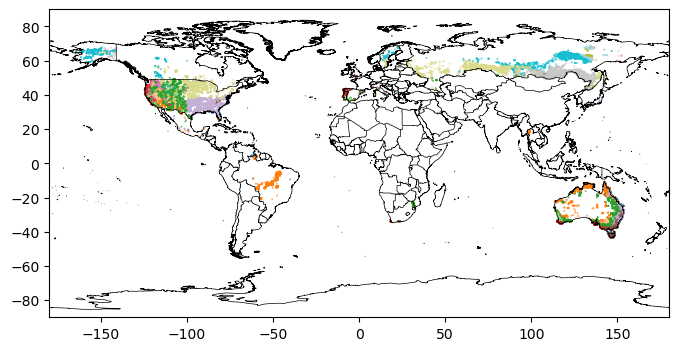

In [81]:
fig,ax = plt.subplots(figsize=(8,4))
cno = pycno.cno(xlim=(-180,180),ylim=(-90,90))
cno.draw('MWDB_Coasts_Countries_1.cnob',ax=ax)
ax.scatter(df['Longitude'].values,df['Latitude'].values,c=df['Koppen Climate'].values,s=0.1,cmap='tab20')

In [85]:
df.groupby(['Biome (Olson)','Koppen Climate']).size()

Biome (Olson)         Koppen Climate
Boreal Forests/Taiga  0.0                 3
                      7.0                64
                      18.0                1
                      19.0               89
                      20.0               72
                                       ... 
Tundra                19.0               15
                      22.0                2
                      23.0              106
                      26.0               26
                      27.0              225
Length: 140, dtype: int64

In [29]:
# SW_df[~((SW_df['RH_min']<SW_RH[1])&
#         (SW_df['RH_min']>SW_RH[0]))].groupby(['Month']).size()

print(SW_df[(SW_df['RH_min']<SW_RH[0])].groupby(['Month']).size().sum()/134)
print(SW_df[(SW_df['FFMC']>SW_FFMC[1])].groupby(['Month']).size().sum()/134)

0.27611940298507465
0.2462686567164179


In [30]:
print(SW_df[(SW_df['RH_min']>SW_RH[1])].groupby(['Month']).size().sum()/134)
print(SW_df[(SW_df['FFMC']<SW_FFMC[0])].groupby(['Month']).size().sum()/134)

0.26119402985074625
0.17164179104477612


In [32]:
BBS_df[((BBS_df['Wind']<QNSL_W[1])&
        (BBS_df['Wind']>QNSL_W[0])&
        (BBS_df['FFDI']<QNSL_FFDI[1])&
        (BBS_df['FFDI']>QNSL_FFDI[0]))].groupby(['Month']).size()

Month
1      70
2      30
3      65
4     125
5     157
6     187
7     236
8     310
9     156
10     52
11     44
12     12
dtype: int64

In [24]:
len(QNSL_BTS_df[QNSL_BTS_df['KBDI']<50])/len(QNSL_BTS_df)

0.8385469223007064

In [47]:
Rx_burn_pct(CA_SN_df,CA_SN_T,CA_SN_RH,CA_SN_W)

0.7845622119815668

In [19]:
Rx_burn_pct(SAUS_MLW_df,SAUS_T,SAUS_RH,SAUS_W)

0.7312430011198209

In [18]:
Rx_burn_pct(PRT_df,PRT_T,PRT_RH,PRT_W)

0.584653291094685

In [20]:
Rx_burn_pct(SW_df,SW_T,SW_RH,SW_W)

0.417910447761194

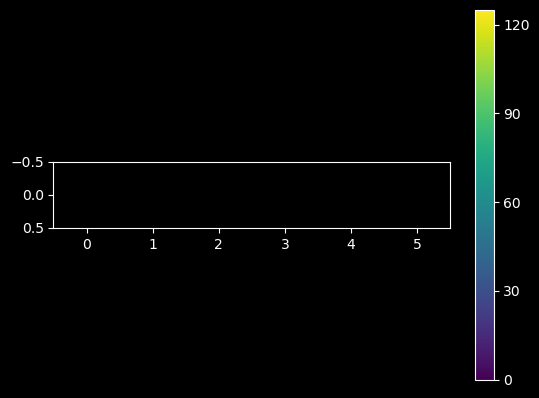

In [7]:
img = plt.imshow(np.array([[0,25,50,75,100,125]]), cmap="viridis")
img.set_visible(False)

plt.colorbar(orientation="vertical",ticks=[0,30,60,90,120])
plt.style.use("dark_background")
plt.savefig('Figures/colorbar.png',transparent=True,bbox_inches='tight')

## Prescriptions Windows from Jonko et al. 2024

* Uses EPA Level II Ecoregions
* Prescriptions downloaded from [Jonko et al. 2024 GitHub](https://github.com/ajonko/RxFire?tab=readme-ov-file)

In [6]:
Rx_df = pd.read_csv('Rx_windows_Jonko.csv',low_memory=False)

In [23]:
# EPA Ecoregions Level II shapefile
EPA_eco = gpd.read_file('EPA_Ecoregion_Level_II/NA_CEC_Eco_Level2.shp').to_crs('EPSG:4326')
Rx_eco_idx = [True if i in np.unique(Rx_df['L2 Ecoregion']) else False for i in EPA_eco['NA_L2CODE'].astype(float)]

# GlobalRx USA data points
US_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(US_df['Longitude'],US_df['Latitude'])]})
US_pts.crs = 'EPSG:4326'

# Which burns are in which EPA Ecoregion for which we have burn prescriptions
USA_join = gpd.sjoin(US_pts,EPA_eco[Rx_eco_idx])

# Add EPA Ecoregions to GlobalRx USA dataframe
US_df['EPA Ecoregion'] = USA_join['NA_L2CODE'].astype(float)
US_df['EPA Eco Name'] = USA_join['NA_L2NAME']

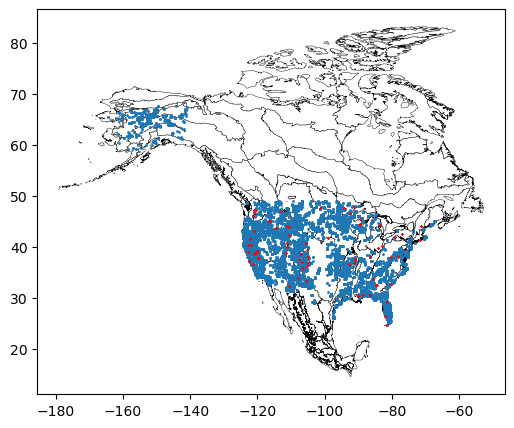

In [66]:
fig,ax = plt.subplots(figsize=(8,5))
EPA_eco.plot(ax=ax,facecolor='white',edgecolor='black',linewidth=0.3)
ax.scatter(US_df['Longitude'],US_df['Latitude'],s=1)
ax.scatter(Rx_df['Longitude'],Rx_df['Latitude'],s=1,color='red',marker='x')

In [95]:
L2_ecos = np.unique(US_df['EPA Ecoregion'].dropna().astype(float))
Rx_L2_mean = Rx_df.groupby(['L2 Ecoregion']).mean()
Rx_L2_min = Rx_df.groupby(['L2 Ecoregion']).min()
Rx_L2_max = Rx_df.groupby(['L2 Ecoregion']).max()

In [128]:
lon_idx = (US_df['Longitude']>=-94.4) & (US_df['Longitude']<=-94.3)
lat_idx = (US_df['Latitude']>=47.6) & (US_df['Latitude']<=47.63)
US_df[US_df['State/Province']=='Minnesota'].loc[lon_idx]

,ID,Latitude,Longitude,Year,Month,Day,Time,DOY,Country,State/Province,...,Topography,Fuelbed Classification (GFD-FCCS),WDPA Name,WDPA Governance,WDPA Ownership,WDPA Designation,WDPA IUCN Category,Timestamp of Update,EPA Ecoregion,EPA Eco Name
4139,Rx20100414-N47.166699-W 94.301522,47.166699,-94.301522,2010,4,14,NaN,104,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,11.1,MEDITERRANEAN CALIFORNIA
4618,Rx20130511-N47.166471-W 94.301703,47.166471,-94.301703,2013,5,11,NaN,131,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,NaN,NaN
4658,Rx20130816-N47.363683-W 94.308237,47.363683,-94.308237,2013,8,16,NaN,228,USA,Minnesota,...,400.0,Mixed Broadleaf and Needleleaf Evergreen Forest,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,10.2,WARM DESERTS
5282,Rx20140422-N47.358434-W 94.308543,47.358434,-94.308543,2014,4,22,NaN,112,USA,Minnesota,...,400.0,Mixed Broadleaf and Needleleaf Evergreen Forest,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,10.1,COLD DESERTS
5680,Rx20140423-N47.166696-W 94.301552,47.166696,-94.301552,2014,4,23,NaN,113,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,8.3,SOUTHEASTERN USA PLAINS
7639,Rx20170505-N47.166648-W 94.301599,47.166648,-94.301599,2017,5,5,NaN,125,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,8.5,MISSISSIPPI ALLUVIAL AND SOUTHEAST USA COASTAL...
8099,Rx20180423-N47.166624-W 94.301625,47.166624,-94.301625,2018,4,23,NaN,113,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,8.1,MIXED WOOD PLAINS
8557,Rx20180903-N44.681965-W 94.358204,44.681965,-94.358204,2018,9,3,NaN,246,USA,Minnesota,...,310.0,Mosaic Forest-Shrubland (50-70%)/Grassland (20...,Mcleod County,Federal or national ministry or agency,State,Waterfowl Production Area,VI,2021-02-18 00:00:00,9.3,WEST-CENTRAL SEMIARID PRAIRIES
9493,Rx20190830-N47.166586-W 94.301542,47.166586,-94.301542,2019,8,30,NaN,242,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2021-02-18 00:00:00,8.1,MIXED WOOD PLAINS
23917,Rx20130503-N47.166471-W 94.301703,47.166471,-94.301703,2013,5,3,NaN,123,USA,Minnesota,...,395.0,inf,NaN,NaN,NaN,NaN,NaN,2024-02-26 11:30:20.450501,8.3,SOUTHEASTERN USA PLAINS


In [115]:
Rx_df

,Site name,Latitude,Longitude,L2 Ecoregion,Fuels (Scott&Burgan Model),Min Temp (K),Max Temp (K),Min RH (%),Max RH (%),Min WS (m/s),Max WS (m/s),Start Date 1,End Date 1
0,"Huron-Mainstee NF, MI",44.334000,-83.638600,5.2,"TU2, TL6, GR2, SH7, TL9",269.26,305.37,27,85,0.00,2.86,0,365
1,"Treehaven UWSP, WI",45.492762,-89.554647,5.2,"SB1, TL3",277.59,291.48,30,70,0.00,4.02,0,365
2,"Cloquet, MN",46.693464,-92.530709,5.2,TL3,269.26,308.15,25,75,0.45,7.15,0,365
3,"Itasca County, MN",47.619423,-94.343987,5.2,SB1,274.82,302.59,20,60,0.00,3.58,0,365
4,"Superior NF, MN",47.724542,-91.276077,5.2,TL6,285.93,302.59,25,60,0.00,5.81,0,365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,"Sacramento Valley Uplands, CA",38.514980,-121.093160,11.1,GR2,283.15,307.59,20,60,0.45,5.36,0,365
82,"Mixed Chaparral, CA",38.996050,-122.655140,11.1,SH5,277.59,302.59,25,70,0.00,4.47,0,365
83,"Lincoln NF, NM",33.353056,-105.682690,13.1,"GR2, TL9, TL3",283.15,297.04,20,35,0.00,1.79,0,365
84,"Lueras, NM",33.827412,-107.890360,13.1,"TL8, GR1, SB1, GR1, TL1",280.37,299.82,15,50,0.00,2.68,0,365


In [138]:
df.groupby(['Fuelbed Classification (GFD-FCCS)']+['Koppen Climate']).size()

Fuelbed Classification (GFD-FCCS)  Koppen Climate                        
Broadleaf Deciduous Forest         Am;Tropical, monsoon                         1
                                   Aw;Tropical, savannah                     1769
                                   BSh;Arid, steppe, hot                      197
                                   BSk;Arid, steppe, cold                      17
                                   BWh;Arid, desert, hot                        1
                                                                             ... 
inf                                Csb;Temperate, dry summer, warm summer     236
                                   Cwa;Temperate, dry winter, hot summer        7
                                   Dfa;Cold, no dry season, hot summer         53
                                   Dfb;Cold, no dry season, warm summer        19
                                   Dfc;Cold, no dry season, cold summer         1
Length: 411, dtype: int6

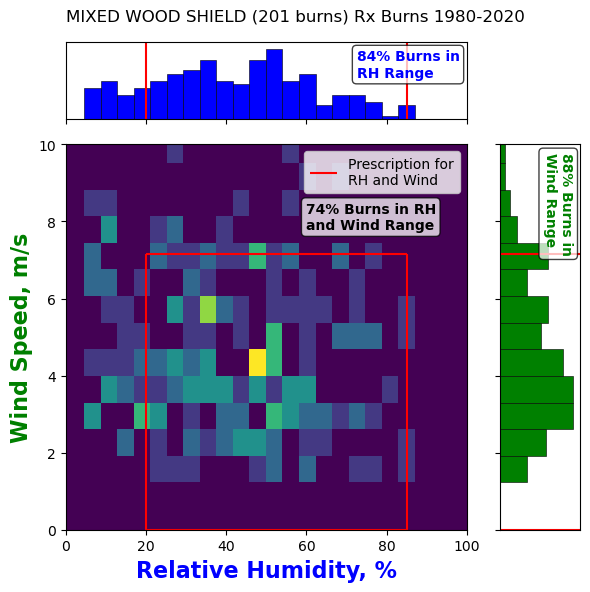

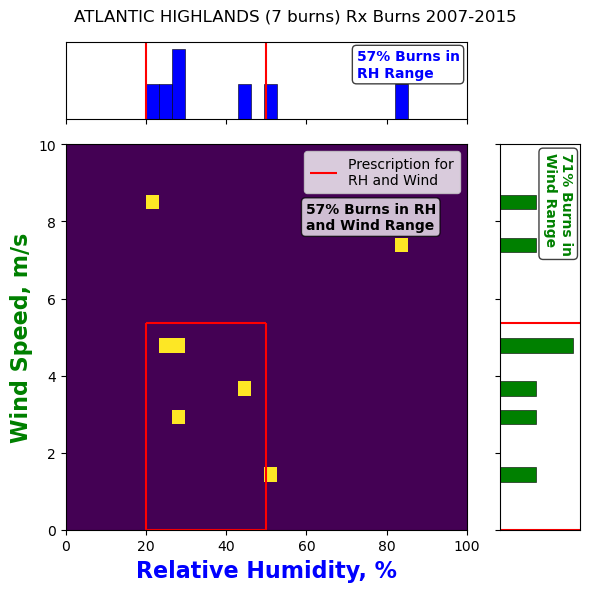

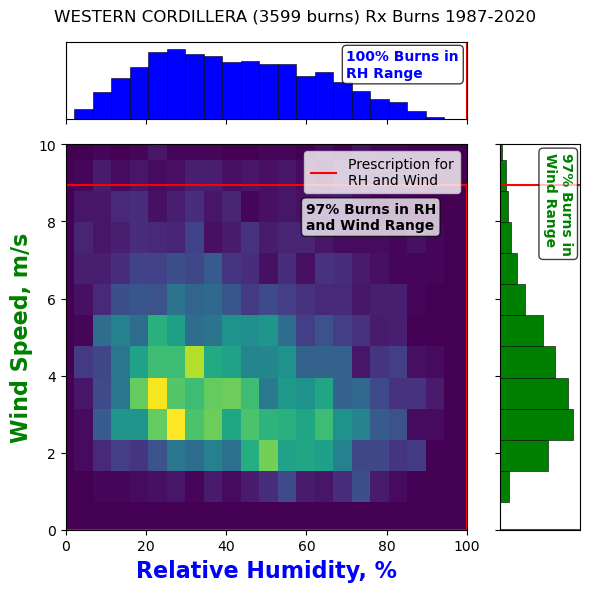

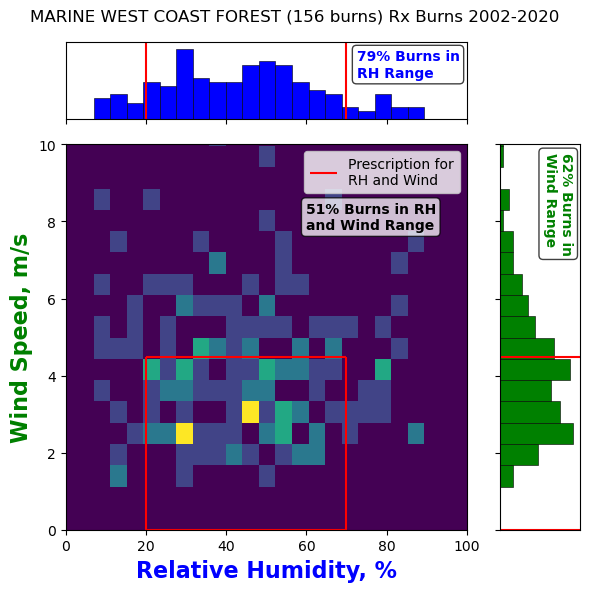

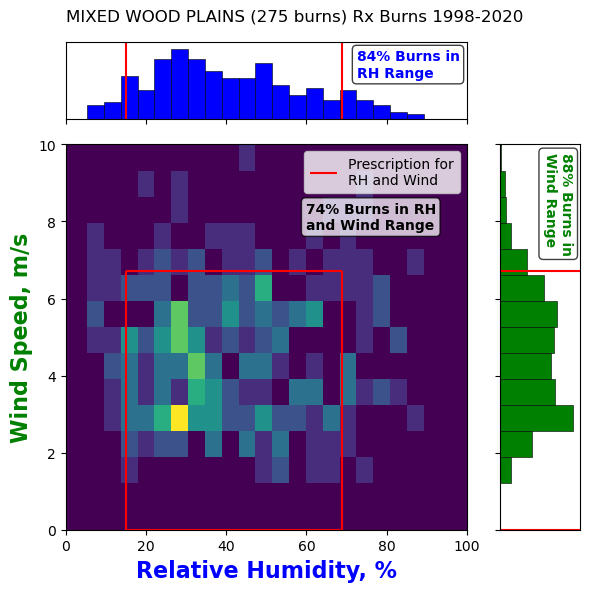

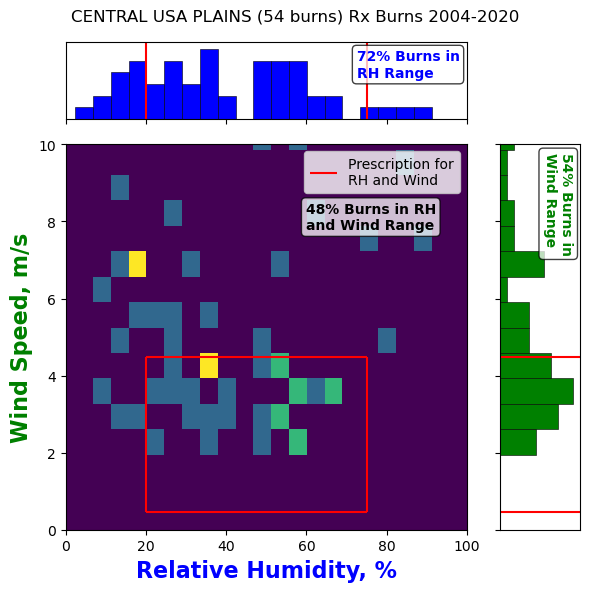

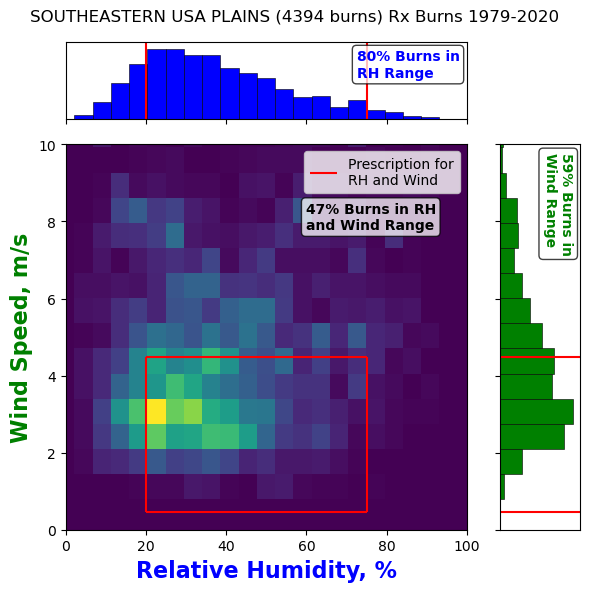

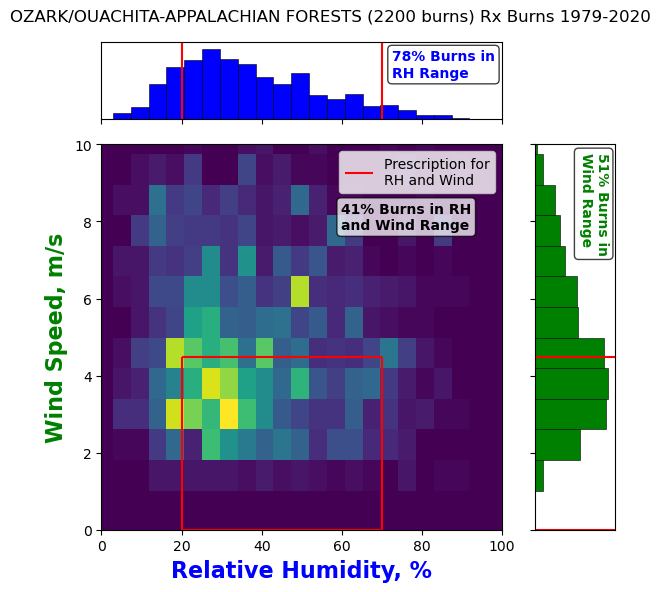

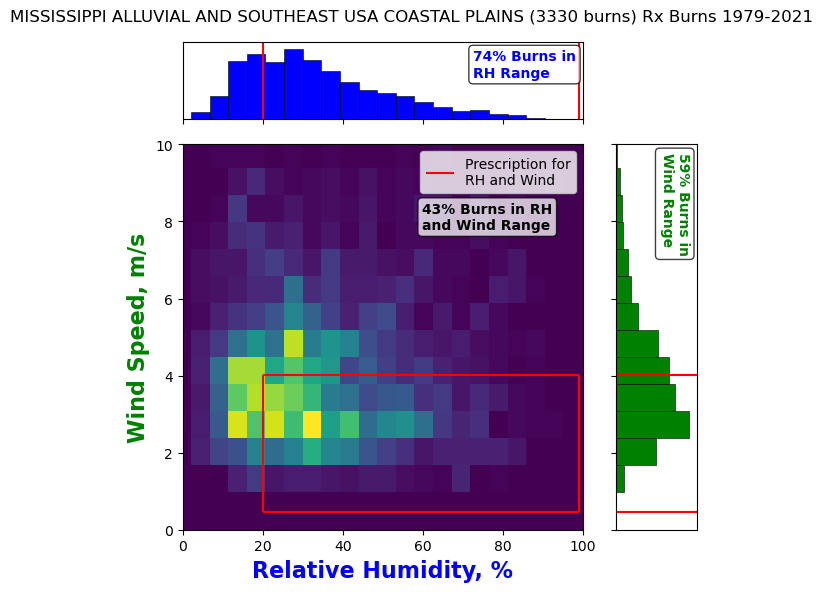

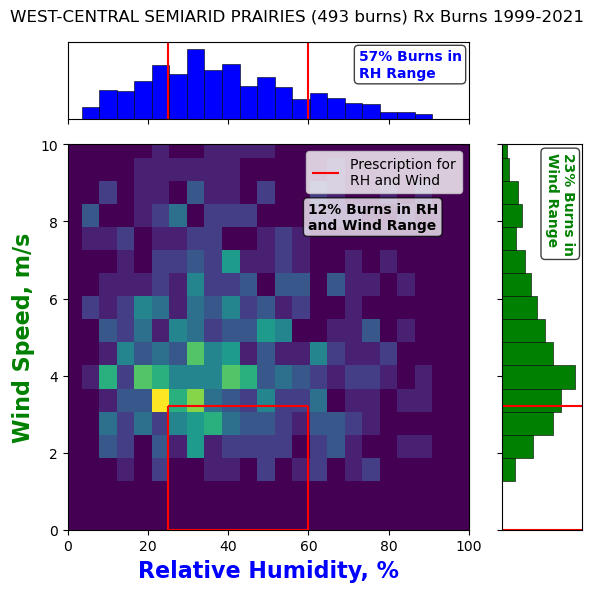

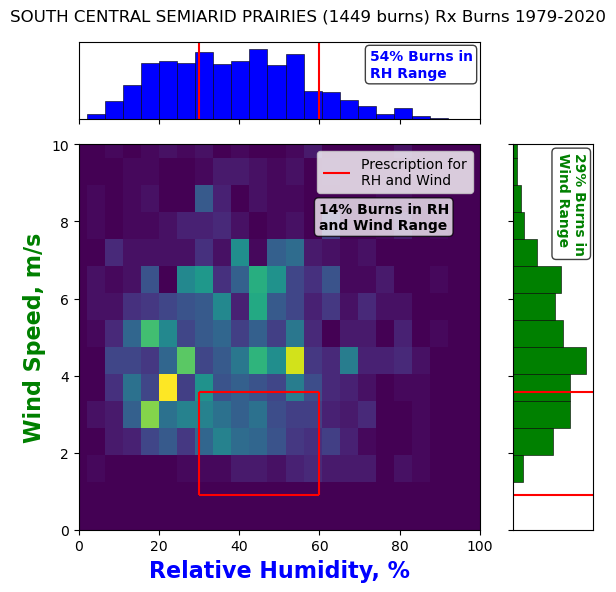

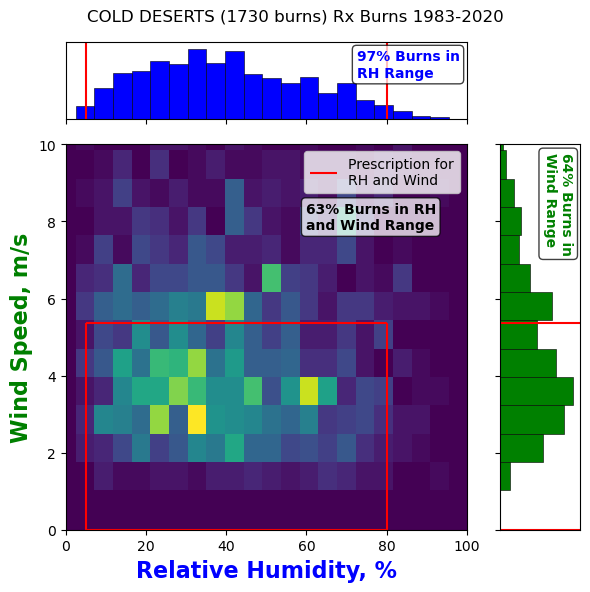

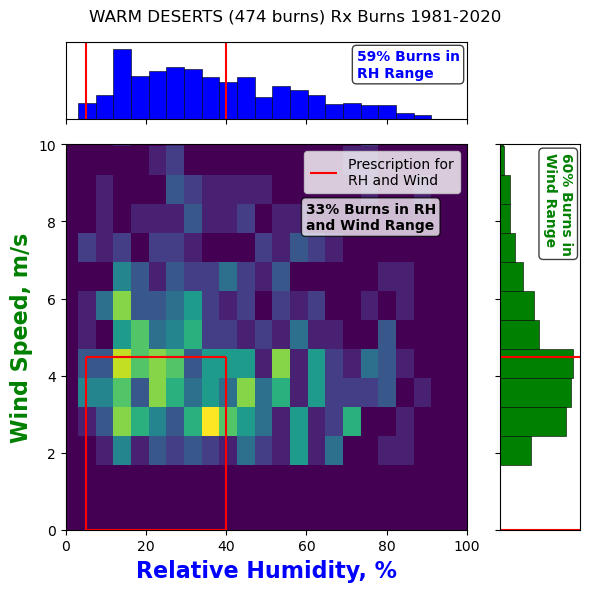

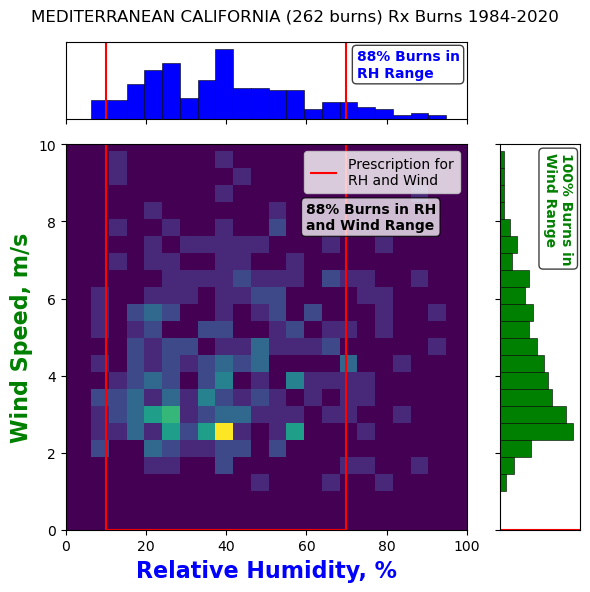

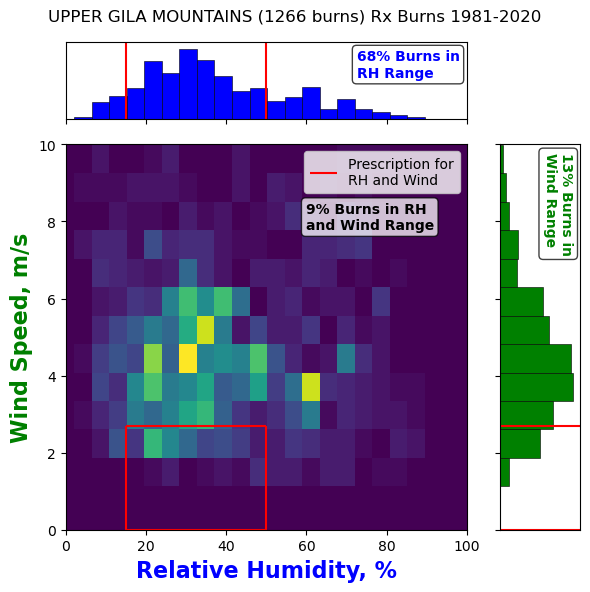

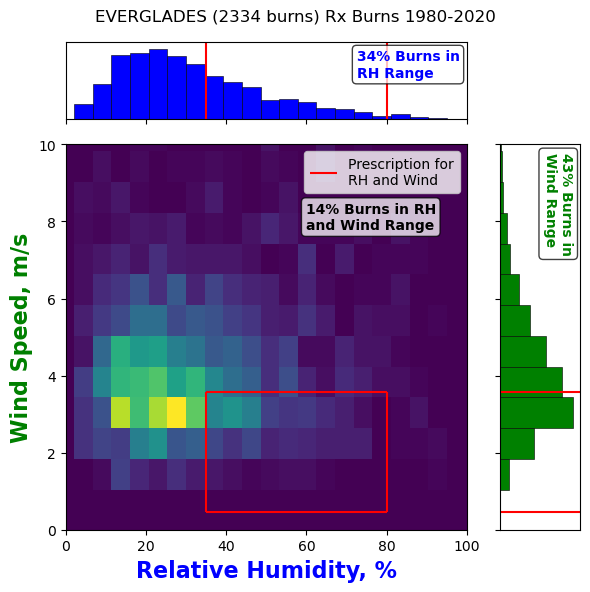

In [111]:
for L2 in L2_ecos:
    L2_RH = [Rx_L2_min.loc[L2]['Min RH (%)'],Rx_L2_max.loc[L2]['Max RH (%)']]
    L2_T = [Rx_L2_min.loc[L2]['Min Temp (K)']-273.15,Rx_L2_max.loc[L2]['Max Temp (K)']-273.15]
    L2_W = [Rx_L2_min.loc[L2]['Min WS (m/s)'],Rx_L2_max.loc[L2]['Max WS (m/s)']]
    eco_df = US_df[US_df['EPA Ecoregion']==L2]
    plot2d_Rx(eco_df,'RH_min','Wind_max',L2_RH,L2_W,eco_df['EPA Eco Name'].iloc[0]+' ('+str(len(eco_df))+' burns)')

## Meteorological distributions

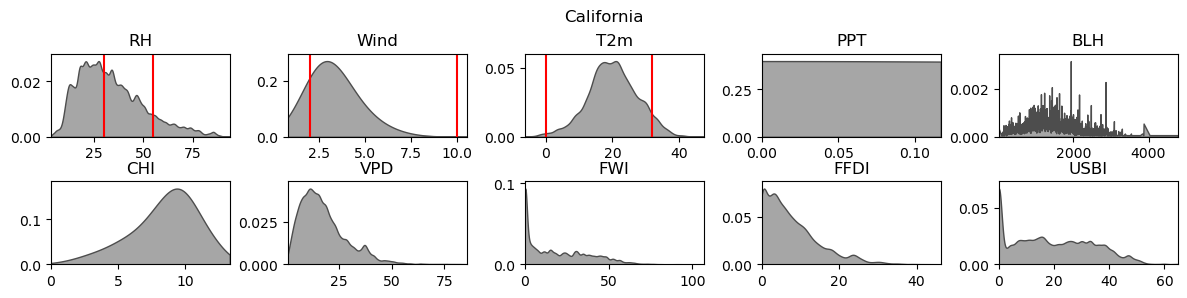

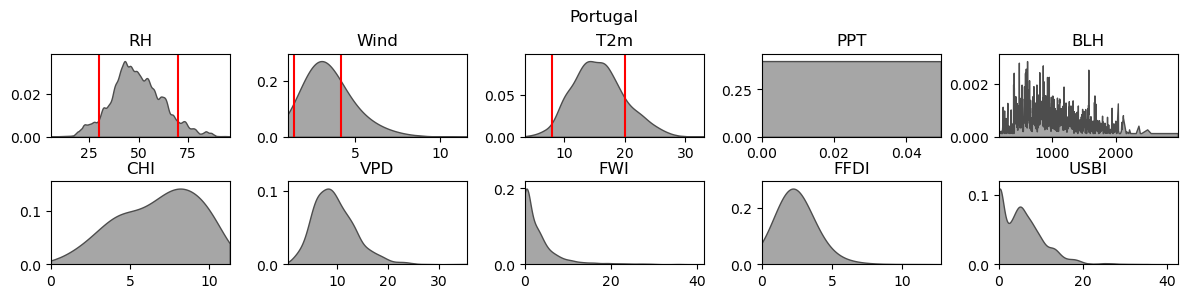

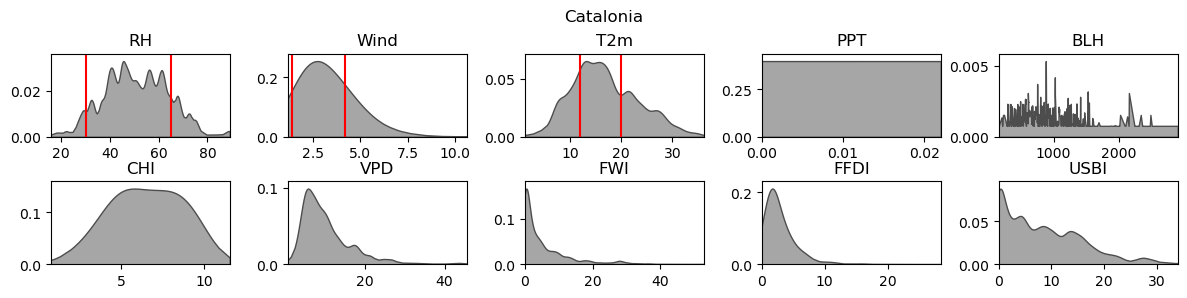

In [31]:
FWIs = ['Wind','T2m','RH','PPT','BLH','CHI','VPD','FWI','FFDI','USBI']

fig_CA,ax_CA = plt.subplots(2,5,figsize=(12,3))
plt.suptitle('California')
plt.tight_layout()
fig_PRT,ax_PRT = plt.subplots(2,5,figsize=(12,3))
plt.suptitle('Portugal')
plt.tight_layout()
fig_CAT,ax_CAT = plt.subplots(2,5,figsize=(12,3))
plt.suptitle('Catalonia')
plt.tight_layout()

ax_CA = ax_CA.ravel()
ax_PRT = ax_PRT.ravel()
ax_CAT = ax_CAT.ravel()

# CA_df.replace([np.inf,-np.inf],np.nan,inplace=True)
# PRT_df.replace([np.inf,-np.inf],np.nan,inplace=True)
# CAT_df.replace([np.inf,-np.inf],np.nan,inplace=True)

i=0
CA_FWI = []
PRT_FWI = []
CAT_FWI = []
for FWI in FWIs:
    CA_X = np.sort(CA_df[FWI].dropna().values)
    PRT_X = np.sort(PRT_df[FWI].dropna().values)
    CAT_X = np.sort(CAT_df[FWI].dropna().values)
    
    CA_kde = KernelDensity(kernel='gaussian').fit(CA_X.reshape(-1,1))
    PRT_kde = KernelDensity(kernel='gaussian').fit(PRT_X.reshape(-1,1))
    CAT_kde = KernelDensity(kernel='gaussian').fit(CAT_X.reshape(-1,1))
    
    CA_Y = np.exp(CA_kde.score_samples(CA_X.reshape(-1,1)))
    PRT_Y = np.exp(PRT_kde.score_samples(PRT_X.reshape(-1,1)))
    CAT_Y = np.exp(CAT_kde.score_samples(CAT_X.reshape(-1,1)))
    
    CA_FWI.append(CA_Y)
    PRT_FWI.append(PRT_Y)
    CAT_FWI.append(CAT_Y)

    ax_CA[i].fill_between(CA_X,np.zeros(np.shape(CA_Y)),CA_Y,facecolor=[0.5,0.5,0.5,0.7],edgecolor=[0.3,0.3,0.3])
    ax_PRT[i].fill_between(PRT_X,np.zeros(np.shape(PRT_Y)),PRT_Y,facecolor=[0.5,0.5,0.5,0.7],edgecolor=[0.3,0.3,0.3])
    ax_CAT[i].fill_between(CAT_X,np.zeros(np.shape(CAT_Y)),CAT_Y,facecolor=[0.5,0.5,0.5,0.7],edgecolor=[0.3,0.3,0.3])
    
    ax_CA[i].set_title(FWI)
    ax_PRT[i].set_title(FWI)
    ax_CAT[i].set_title(FWI)
    
    # Add limits
    if FWI=='Wind':
        ax_CA[i].vlines(CA_W,ymin=0,ymax=1,colors='red')
        ax_PRT[i].vlines(PRT_W,ymin=0,ymax=1,colors='red')
        ax_CAT[i].vlines(CAT_W,ymin=0,ymax=1,colors='red')
#         W_pct = (len(CA_X[(CA_X>CA_W[0])&(CA_X<CA_W[1])])/len(CA_X))*100
#         ax[i].text(str(round(W_pct)),np.mean(W_range),max(Y)*0.9)
    if FWI=='T2m':
        ax_CA[i].vlines(CA_T,ymin=0,ymax=1,colors='red')
        ax_PRT[i].vlines(PRT_T,ymin=0,ymax=1,colors='red')
        ax_CAT[i].vlines(CAT_T,ymin=0,ymax=1,colors='red')
    if FWI=='RH':
        ax_CA[i].vlines(CA_RH,ymin=0,ymax=1,colors='red')
        ax_PRT[i].vlines(PRT_RH,ymin=0,ymax=1,colors='red')
        ax_CAT[i].vlines(CAT_RH,ymin=0,ymax=1,colors='red')
#         RH_pct = len(CA_X[(CA_X>CA_RH[0])&(CA_X<CA_RH[1])])/len(CA_X)*100
#         ax[i].text(str(round(RH_pct)),np.mean(RH_range),max(Y)*0.9)
    
    ax_CA[i].set_xlim([np.min(CA_X),np.max(CA_X)])
    ax_CA[i].set_ylim([0,np.max(CA_Y)*1.1])
    ax_PRT[i].set_xlim([np.min(PRT_X),np.max(PRT_X)])
    ax_PRT[i].set_ylim([0,np.max(PRT_Y)*1.1])
    ax_CAT[i].set_xlim([np.min(CAT_X),np.max(CAT_X)])
    ax_CAT[i].set_ylim([0,np.max(CAT_Y)*1.1])
    
    i+=1
    